# qlpca and princals: pipelines, results and what differs

This notebook compares the `qlpca` package (quasi-linear PCA; Lavado & Calapez 2011, `lavado2011ijam`;
Lavado 2012, `lavado2012phd`) with `princals` from the Gifi system (`gifi1991nonlinear`): the R package **Gifi 1.0-0**
(Mair, De Leeuw & Groenen; `mair2025gifi`) and its Python port **pyGifi** (commit `7aa81ed`;
`perumal2025pygifi`).

* Inputs and settings: [`manifest.json`](manifest.json) (data, explicit knots per variable, degree, `ndim`,
  `ordinal`, tolerances). Computations: [`compare.py`](compare.py). R results:
  [`generate_r_ground_truth.R`](generate_r_ground_truth.R), run by the manual workflow
  `.github/workflows/r-ground-truth.yml`; its JSON files go to `results/r_ground_truth/`.
* Gifi and pyGifi are GPL-3. They are only imported or called here; short quotations of their source lines
  are given with file and line number. No code of theirs is in `qlpca`.
* pyGifi fits are cached in `results/pygifi/` (the monotone degree-2 fits take minutes);
  `python compare.py --refresh` recomputes them.

Data: the cylinder problem (`make_cylinder`, n = 51, noise 0, 0.10, 0.25, `random_state=0`); thesis
chapter 4 (`load_st_gender`, n = 15); `neumann` (3 continuous variables, loaded from pyGifi at run time);
UCI *Gas Turbine CO and NOx Emission* (doi:10.24432/C5WC95, CC BY 4.0; year 2015, a reproducible sample of
400 hourly records, `random_state=2015`; downloaded at run time into the git-ignored `.cache/`).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import compare as c
from qlpca import QLPCA, ExtrapolationWarning
from qlpca.plots import set_style
from qlpca.splines import bspline_basis, ispline_basis, knot_sequence
import pygifi

set_style()
pd.set_option("display.precision", 6)
MAN = c.load_manifest()
NDIM = MAN["ndim"]
fits, summary = c.run_all(verbose=False)           # qlpca live; pyGifi from results/pygifi/ (cached)
R_AVAILABLE = {name: c.load_r_ground_truth(name) is not None for name in MAN["datasets"]}
try:
    import pygifi_rng                              # R's random number generator (C extension of pyGifi)
    HAVE_RNG = True
except ImportError:
    HAVE_RNG = False
print("R ground truth available:", {k: v for k, v in R_AVAILABLE.items()})
print("pygifi_rng available:", HAVE_RNG)

R ground truth available: {'cylinder_0': False, 'cylinder_10': False, 'cylinder_25': False, 'st_gender': False, 'neumann': False, 'gas_turbine': False}
pygifi_rng available: False


## a) The pipelines side by side

| step | thesis (2012 MATLAB) = `qlpca(legacy=True)` | `qlpca` default | `princals` (Gifi 1.0-0; pyGifi 7aa81ed) |
|---|---|---|---|
| input | continuous variables, standardised | continuous variables, standardised | numeric columns passed through unchanged; factors converted to numbers |
| basis | I-splines (pseudo-indicator matrix), columns standardised | B-splines, centred (I-splines + intercept if `monotone=True`) | B-splines on the original values, centred |
| default knots | `n_knots` interior knots at percentiles | `n_knots=1` at the median (percentile rule) | a knot at every distinct value (`levels="ordinal"`, the default) |
| start | first p columns of the standardised basis | PCA scores + `n_init=10` random orthonormal starts; lowest loss kept | R: `set.seed(123)` + `rnorm`; pyGifi default: SVD of the stacked centred bases |
| update of f_j | regression on the basis | projection on the centred basis | projection of a majorised target on the centred basis (same projection for princals) |
| update of X, A | eigen-decomposition of F'F | truncated SVD of F | one step of orthogonal iteration: X = GS(centre(HA')) |
| monotonicity | — | optional: NNLS on I-splines (coefficients ≥ 0) | default (`ordinal=TRUE`): Dykstra's alternating projections, spline space ↔ isotone cone |
| stopping | abs(loss change) < tol | abs(loss change) < tol (`tol=1e-6`) | loss decrease < eps (`eps=1e-6`) |

Source lines (Gifi R 1.0-0, CRAN source; pyGifi at commit `7aa81ed`; qlpca at this commit):

* Input. Gifi [`R/princals.R:8`](https://github.com/cran/Gifi/blob/1.0-0/R/princals.R#L8) `data <- makeNumeric(data)`;
  [`R/gifiUtilities.R:15-20`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiUtilities.R#L15-L20): only `is.factor` columns are converted,
  otherwise `column <- x[,i]  ## not a factor column`.
* Basis. Gifi [`R/gifiStructures.R:12`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiStructures.R#L12) `work <- data[there]`,
  [`:32`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiStructures.R#L32) `basis <- bsplineBasis (work, degree, knots)`,
  [`:40`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiStructures.R#L40) `qr <- gsRC (center (basis))`.
  qlpca [`core.py:326-328`](../../src/qlpca/core.py#L326-L328) (I- or B-splines), legacy
  [`core.py:287`](../../src/qlpca/core.py#L287) (standardised I-splines).
* Default knots. Gifi [`R/prepspline.R:12-14`](https://github.com/cran/Gifi/blob/1.0-0/R/prepspline.R#L12-L14): `"ordinal"` →
  `knotsGifi(data[,i], "D")`; [`R/knotsGifi.R:9`](https://github.com/cran/Gifi/blob/1.0-0/R/knotsGifi.R#L9) `## D ... knots at the data points`.
  pyGifi [`utils/splines.py:151`](https://github.com/vam-math/pyGifi/blob/7aa81ed/pygifi/utils/splines.py#L151) `'D': Knots at each unique data value (drop min/max)`.
* Start. Gifi [`R/gifiEngine.R:8`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiEngine.R#L8) `set.seed(123)`,
  [`:15-16`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiEngine.R#L15-L16) `x <- matrix(rnorm(nobs * ndim), nobs, ndim)`, `x <- gsRC(center(x))$q`.
  pyGifi [`core/engine.py:191-198`](https://github.com/vam-math/pyGifi/blob/7aa81ed/pygifi/core/engine.py#L191-L198) (SVD start by default) and
  [`:140-145`](https://github.com/vam-math/pyGifi/blob/7aa81ed/pygifi/core/engine.py#L140-L145) (`r_seed`: R's generator through the C extension `pygifi_rng`).
  qlpca [`core.py:349-351`](../../src/qlpca/core.py#L349-L351).
* Target and update. Gifi [`R/gifiEngine.R:58-60`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiEngine.R#L58-L60)
  `target <- hh + tcrossprod (rs, aa) / kappa`; [`:128`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiEngine.R#L128) `x <- gsRC (center (xz))$q`.
  qlpca [`core.py:141`](../../src/qlpca/core.py#L141) `U, S, Vt = np.linalg.svd(F, full_matrices=False)`.
* Monotonicity. Gifi [`R/coneRegression.R:81`](https://github.com/cran/Gifi/blob/1.0-0/R/coneRegression.R#L81) calls `dykstra`;
  [`:86-105`](https://github.com/cran/Gifi/blob/1.0-0/R/coneRegression.R#L86-L105): inner loop with `itmax = 1000`, `eps = 1e-6`, stops when
  `max(abs(x1 - x2)) < eps` and returns `(x1 + x2) / 2`. pyGifi [`utils/isotone.py:299`](https://github.com/vam-math/pyGifi/blob/7aa81ed/pygifi/utils/isotone.py#L299).
  qlpca [`core.py:335`](../../src/qlpca/core.py#L335) `nnls(Cs[j], y, ...)`.
* Stopping. Gifi [`R/gifiEngine.R:124`](https://github.com/cran/Gifi/blob/1.0-0/R/gifiEngine.R#L124) `((fold - fnew) < eps)`;
  pyGifi [`core/engine.py:396`](https://github.com/vam-math/pyGifi/blob/7aa81ed/pygifi/core/engine.py#L396); qlpca [`core.py:147`](../../src/qlpca/core.py#L147)
  `abs(prev - loss) < tol`.

### princals does not discretise numeric variables

The code below checks it on the chapter 4 data with pyGifi: the numeric columns are unchanged by
`make_numeric`; the default knots are the distinct observed values; and with explicit knots the fitted
transformation is exactly piecewise linear in the original values, with as many distinct transformed values as
distinct data values (no grouping into categories).

In [2]:
df = c.load_dataset("st_gender", MAN).reset_index(drop=True)
x = df["researchers"].to_numpy()

print("make_numeric leaves numeric columns unchanged:",
      np.array_equal(np.asarray(pygifi.make_numeric(df), float), df.to_numpy()))
kD = np.asarray(pygifi.knots_gifi(df[["researchers"]], "D")[0], float)
print("default ('D') knots = distinct values without min and max:",
      np.array_equal(kD, np.unique(x)[1:-1]), f"({len(kD)} knots for n = {len(x)})")

p = c.run_pygifi(df, "knots1", MAN, "st_gender")
t = p["transform"][:, 0]
k = MAN["knots"]["st_gender"]["1"]["researchers"]
G = np.column_stack([np.ones_like(x), x, np.maximum(x - k[0], 0)])   # piecewise linear, knot at k
resid = t - G @ np.linalg.lstsq(G, t, rcond=None)[0]
print(f"transform of 'researchers' = piecewise-linear function of the raw values: max residual {np.abs(resid).max():.1e}")
print("distinct transformed values / distinct data values:",
      len(np.unique(t.round(12))), "/", len(np.unique(x)))

make_numeric leaves numeric columns unchanged: True
default ('D') knots = distinct values without min and max: True (13 knots for n = 15)


transform of 'researchers' = piecewise-linear function of the raw values: max residual 2.2e-16
distinct transformed values / distinct data values: 15 / 15


## b) Same knots, degree 1, no monotonicity

The knots are those of `qlpca` (percentile rule), written explicitly in the manifest and passed to all three
implementations (`degrees=1`, `ordinal=FALSE`, `eps=1e-12`). qlpca keeps the best of the PCA start and 10
random starts; pyGifi uses its default SVD start; R uses its fixed seed. "max |Δ|" columns compare the
first two eigenvalues; "1 − |r|" is the largest value over variables of one minus the absolute correlation
between the two transformations.

In [3]:
cols = ["dataset", "run", "n", "m", "qlpca_ev1", "qlpca_ev2", "pygifi_ev1", "pygifi_ev2", "gifi_r_ev1", "gifi_r_ev2",
        "qlpca_vs_pygifi_evals", "qlpca_vs_pygifi_transform_corr", "qlpca_vs_pygifi_objectscores",
        "qlpca_vs_gifi_r_evals", "qlpca_vs_gifi_r_transform_corr", "r_ground_truth"]
same = summary[summary.run.isin(["knots1", "knots2"])].reindex(columns=cols)
same = same.rename(columns={"qlpca_vs_pygifi_evals": "max|Δ| qlpca-pyGifi", "qlpca_vs_pygifi_transform_corr": "1-|r| qlpca-pyGifi",
                            "qlpca_vs_pygifi_objectscores": "max|Δ X| qlpca-pyGifi",
                            "qlpca_vs_gifi_r_evals": "max|Δ| qlpca-R", "qlpca_vs_gifi_r_transform_corr": "1-|r| qlpca-R"})
same

,dataset,run,n,m,qlpca_ev1,qlpca_ev2,pygifi_ev1,pygifi_ev2,gifi_r_ev1,gifi_r_ev2,max|Δ| qlpca-pyGifi,1-|r| qlpca-pyGifi,max|Δ X| qlpca-pyGifi,max|Δ| qlpca-R,1-|r| qlpca-R,r_ground_truth
0,cylinder_0,knots1,51,12,7.031845,4.393143,7.031841,4.393146,NaN,NaN,3.319280e-06,8.487322e-12,0.000027,NaN,NaN,pending
1,cylinder_0,knots2,51,12,7.017493,4.673430,7.017484,4.673439,NaN,NaN,8.962714e-06,5.049650e-11,0.000050,NaN,NaN,pending
5,cylinder_10,knots1,51,12,6.737547,4.509111,6.737545,4.509113,NaN,NaN,2.159994e-06,9.179768e-12,0.000039,NaN,NaN,pending
6,cylinder_10,knots2,51,12,6.888681,4.634553,6.888675,4.634559,NaN,NaN,6.261213e-06,2.105882e-11,0.000041,NaN,NaN,pending
8,cylinder_25,knots1,51,12,6.193599,4.511297,6.193598,4.511299,NaN,NaN,1.740156e-06,4.430234e-12,0.000102,NaN,NaN,pending
9,cylinder_25,knots2,51,12,6.510347,4.497840,6.510341,4.497847,NaN,NaN,6.650939e-06,1.319034e-11,0.000053,NaN,NaN,pending
11,st_gender,knots1,15,11,4.581640,2.997557,4.581641,2.997557,NaN,NaN,5.233976e-07,2.031751e-10,0.000031,NaN,NaN,pending
12,st_gender,knots2,15,11,4.758890,3.637180,4.758889,3.637181,NaN,NaN,8.726622e-07,2.571521e-11,0.000012,NaN,NaN,pending
16,neumann,knots1,65,3,1.874444,1.115132,1.874444,1.115131,NaN,NaN,3.785102e-07,1.004318e-10,0.000035,NaN,NaN,pending
17,neumann,knots2,65,3,1.876965,1.117621,1.876965,1.117621,NaN,NaN,3.149545e-07,6.349210e-11,0.000037,NaN,NaN,pending


qlpca vs pyGifi within tolerance {'evals': 1e-05, 'transform_corr': 1e-08, 'objectscores': 0.0005, 'loadings': 0.0001}: 12 of 12 cases
Gifi (R): pending (run the R ground-truth workflow and add the JSON files)


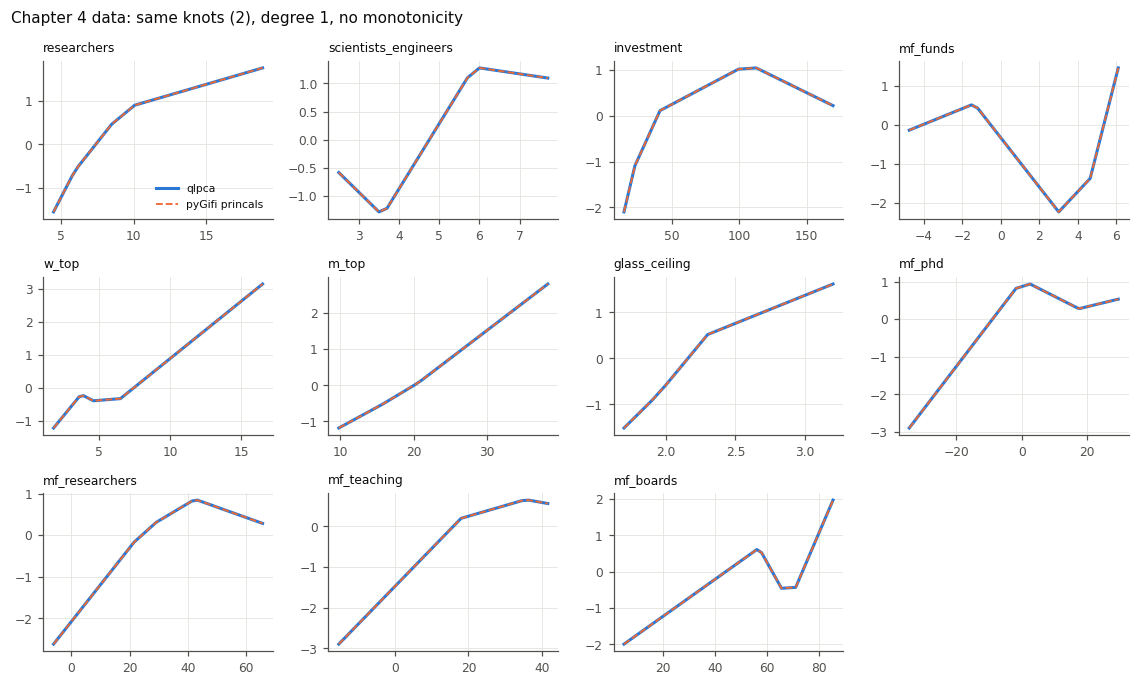

In [4]:
tol = MAN["tolerances"]["unrestricted"]
ok = summary[summary.run.isin(["knots1", "knots2"])]["qlpca_vs_pygifi_within_tol"]
print(f"qlpca vs pyGifi within tolerance {tol}: {int(ok.sum())} of {len(ok)} cases")
if "qlpca_vs_gifi_r_within_tol" in summary:
    okr = summary[summary.run.isin(["knots1", "knots2"])]["qlpca_vs_gifi_r_within_tol"].dropna()
    print(f"qlpca vs Gifi (R): {int(okr.sum())} of {len(okr)} cases")
else:
    print("Gifi (R): pending (run the R ground-truth workflow and add the JSON files)")
fig = c.plot_transformations(c.load_dataset("st_gender", MAN), fits["st_gender", "knots2"],
                             title="Chapter 4 data: same knots (2), degree 1, no monotonicity")
c.save_figure(fig, "nb_b_same_knots_transformations_st_gender")
plt.show()

**Iterations and tolerance.** Both programs stop when the loss changes by less than `eps` in one iteration,
which does not bound the distance to the optimum. With `eps=1e-12` the eigenvalues still differ in the
sixth decimal; the tolerances of the comparison (manifest) are set accordingly.

In [5]:
df = c.load_dataset("cylinder_0", MAN)
rows = []
for eps in (1e-6, 1e-9, 1e-12):
    man = dict(MAN, fit=dict(MAN["fit"], eps=eps))
    q = c.run_qlpca(df, "knots1", man, "cylinder_0", n_init=0)
    p = c.run_pygifi(df, "knots1", man, "cylinder_0")
    rows.append({"eps": eps, "qlpca ev1, ev2": q["evals"][:2].round(6), "qlpca iterations": q["ntel"],
                 "pyGifi ev1, ev2": p["evals"][:2].round(6), "pyGifi iterations": p["ntel"],
                 "max|Δ|": np.abs(q["evals"][:2] - p["evals"][:2]).max()})
pd.DataFrame(rows)

,eps,"qlpca ev1, ev2",qlpca iterations,"pyGifi ev1, ev2",pyGifi iterations,max|Δ|
0,1.000000e-06,"[7.030831, 4.394155]",28,"[7.027104, 4.397855]",18,0.003727
1,1.000000e-09,"[7.03181, 4.393178]",43,"[7.031702, 4.393285]",34,0.000108
2,1.000000e-12,"[7.031845, 4.393143]",59,"[7.031841, 4.393146]",50,0.000003


## c) The basis: B-splines and I-splines plus a constant

For the same degree and knots, the B-spline basis B and the I-spline basis with a constant column [1, I]
span the same space: the orthogonal projectors on their column spaces coincide. The unrestricted transformation
is therefore the same with either basis. Their conditioning differs: below, condition numbers on 60 equally
spaced points, knots at the percentiles.

,degree,interior knots,columns B,"columns [1, I]","max |P_B - P_[1,I]|",cond(B),"cond([1, I])"
0,1,1,3,3,5.412337e-16,1.877334,6.692280
1,1,2,4,4,1.249001e-15,1.902601,8.956300
2,1,5,7,7,3.330669e-16,1.867683,15.578889
3,1,10,12,12,1.221245e-15,1.821013,26.395081
4,2,1,4,4,1.942890e-15,2.946129,14.745223
5,2,2,5,5,4.996004e-16,3.043581,17.983943
6,2,5,8,8,9.992007e-16,3.005222,28.192983
7,2,10,13,13,1.554312e-15,2.907387,45.100633


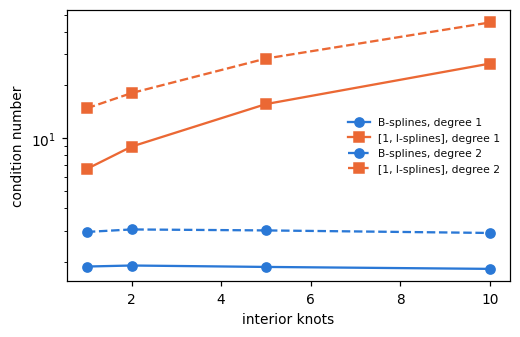

In [6]:
x = np.linspace(0, 1, 60)


def projector(M):
    Q, s, _ = np.linalg.svd(M, full_matrices=False)
    Q = Q[:, s > 1e-10 * s[0]]
    return Q @ Q.T


rows = []
for degree in (1, 2):
    for r in (1, 2, 5, 10):
        kn = knot_sequence(x, degree, r)
        B = bspline_basis(x, degree, kn)
        I1 = np.column_stack([np.ones_like(x), ispline_basis(x, degree, kn)])
        rows.append({"degree": degree, "interior knots": r, "columns B": B.shape[1], "columns [1, I]": I1.shape[1],
                     "max |P_B - P_[1,I]|": np.abs(projector(B) - projector(I1)).max(),
                     "cond(B)": np.linalg.cond(B), "cond([1, I])": np.linalg.cond(I1)})
basis = pd.DataFrame(rows)
display(basis)

fig, ax = plt.subplots(figsize=(5.2, 3.2))
for degree, ls in ((1, "-"), (2, "--")):
    d = basis[basis.degree == degree]
    ax.plot(d["interior knots"], d["cond(B)"], ls, marker="o", color=c.BLUE, label=f"B-splines, degree {degree}")
    ax.plot(d["interior knots"], d["cond([1, I])"], ls, marker="s", color=c.ORANGE, label=f"[1, I-splines], degree {degree}")
ax.set_yscale("log"); ax.set_xlabel("interior knots"); ax.set_ylabel("condition number")
ax.legend(fontsize=7, frameon=False)
c.save_figure(fig, "nb_c_condition_numbers")
plt.show()

## d) Each package's defaults on continuous data

`qlpca` default: `QLPCA(n_components=2)`, one interior knot at the median, no monotonicity, PCA start plus
10 random starts. `princals` default: `levels="ordinal"`, a knot at every distinct value, monotone
transformations, `eps=1e-6`. Linear PCA is `QLPCA(n_knots=0)`. Parameters per variable: rank of the centred
basis (degree + interior knots for qlpca; for princals up to the number of distinct values minus one).

In [7]:
rows = []
for name in MAN["datasets"]:
    df = c.load_dataset(name, MAN)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pca = QLPCA(n_components=NDIM, n_knots=0).fit(df)
    s = summary[(summary.dataset == name) & (summary.run == "defaults")].iloc[0]
    rows.append({"dataset": name, "n": df.shape[0], "m": df.shape[1], "linear PCA": pca.vaf_.sum(),
                 "qlpca default": s.qlpca_vaf2, "princals default (pyGifi)": s.pygifi_vaf2,
                 "princals default (R)": s.gifi_r_vaf2,
                 "params/variable qlpca": s.qlpca_params_mean, "params/variable princals": s.pygifi_params_mean})
defaults = pd.DataFrame(rows)
defaults

,dataset,n,m,linear PCA,qlpca default,princals default (pyGifi),princals default (R),params/variable qlpca,params/variable princals
0,cylinder_0,51,12,82.158246,95.208221,99.988706,NaN,2.0,50.000000
1,cylinder_10,51,12,79.505702,93.722146,99.992977,NaN,2.0,50.000000
2,cylinder_25,51,12,69.543423,89.207468,99.998157,NaN,2.0,50.000000
3,st_gender,15,11,61.886253,68.901771,82.941362,NaN,2.0,14.000000
4,neumann,65,3,98.848115,99.652446,99.978632,NaN,2.0,40.666667
5,gas_turbine,400,9,79.797932,82.202221,86.706841,NaN,2.0,329.000000


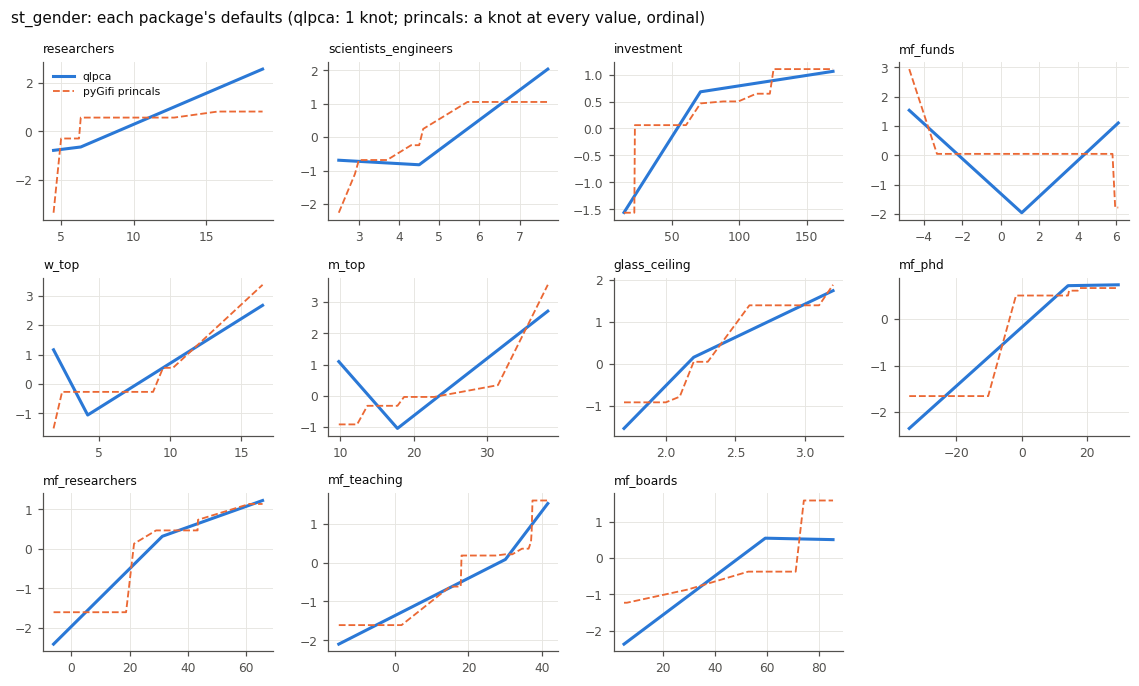

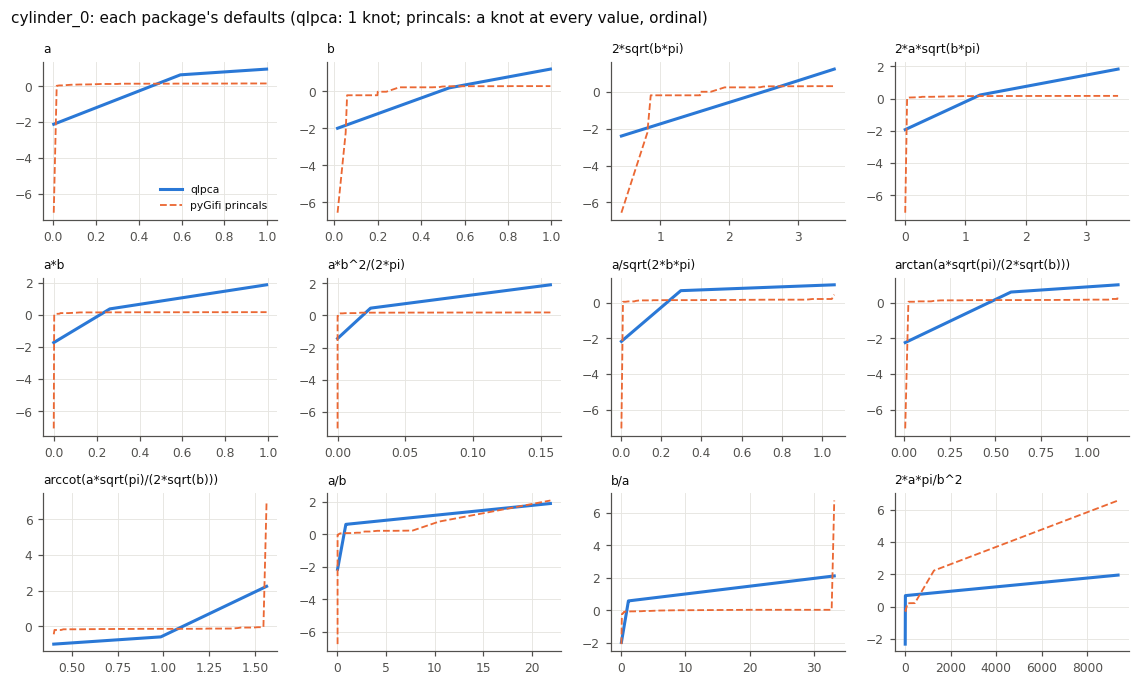

In [8]:
for name in ("st_gender", "cylinder_0"):
    res = fits[name, "defaults"]
    fig = c.plot_transformations(c.load_dataset(name, MAN), res,
                                 title=f"{name}: each package's defaults (qlpca: 1 knot; princals: a knot at every value, ordinal)")
    c.save_figure(fig, f"nb_d_defaults_transformations_{name}")
    plt.show()

With a knot at every distinct value and the ordinal restriction, the princals transformations are step-like:
the monotone fit merges neighbouring values into plateaus. The number of distinct transformed values per
variable (chapter 4 data) is computed below.

In [9]:
df = c.load_dataset("st_gender", MAN)
T = fits["st_gender", "defaults"]["pygifi"]["transform"]
pd.DataFrame({"distinct data values": df.nunique().to_numpy(),
              "distinct princals values (defaults)": [len(np.unique(T[:, j].round(10))) for j in range(df.shape[1])]},
             index=df.columns).T

,researchers,scientists_engineers,investment,mf_funds,w_top,m_top,glass_ceiling,mf_phd,mf_researchers,mf_teaching,mf_boards
distinct data values,15,15,15,15,15,15,15,15,15,15,15
distinct princals values (defaults),4,6,6,3,4,5,5,4,6,8,4


## e) Local optima and starts

Chapter 4 data, 2 knots (same knots for both packages), degree 1, no monotonicity, `eps=1e-12`:
50 random starts of pyGifi (`init_x`, standard normal matrices with seeds 0-49) and 50 random starts of qlpca
(`n_init=50`, orthonormal random matrices), compared with the qlpca PCA start, pyGifi's default SVD start and
R's fixed seed (`set.seed(123)` inside the engine, not exposed as an argument).

In [10]:
name, run = "st_gender", "knots2"
df = c.load_dataset(name, MAN)
m = df.shape[1]
vaf_pg = []
for seed in range(50):
    X0 = np.random.default_rng(seed).standard_normal((df.shape[0], NDIM))
    vaf_pg.append(100 * c.run_pygifi(df, run, MAN, name, init_x=X0)["evals"][:NDIM].sum() / m)
vaf_pg = np.array(vaf_pg)

q = c.run_qlpca(df, run, MAN, name, n_init=50)
vaf_q = 100 * (m - q["model"].losses_) / m          # losses_[0] is the PCA start
vaf_svd = 100 * fits[name, run]["pygifi"]["evals"][:NDIM].sum() / m
marks = {"qlpca PCA start": vaf_q[0], "qlpca kept (best of 51)": vaf_q.max(), "pyGifi default (SVD start)": vaf_svd}
if R_AVAILABLE[name]:
    marks["Gifi (R), set.seed(123)"] = 100 * fits[name, run]["gifi_r"]["evals"][:NDIM].sum() / m
if HAVE_RNG:
    marks["pyGifi r_seed=123 (R generator)"] = 100 * c.run_pygifi(df, run, MAN, name, r_seed=123)["evals"][:NDIM].sum() / m
print("pyGifi, 50 random starts: VAF from", vaf_pg.min().round(2), "to", vaf_pg.max().round(2),
      "| distinct solutions (2 decimals):", np.unique(vaf_pg.round(2)).tolist())
print("qlpca, 50 random starts: VAF from", vaf_q[1:].min().round(2), "to", vaf_q[1:].max().round(2),
      "| distinct solutions (2 decimals):", np.unique(vaf_q[1:].round(2)).tolist())
pd.Series(marks, name="VAF (%)").round(4)

pyGifi, 50 random starts: VAF from 70.55 to 76.33 | distinct solutions (2 decimals): [70.55, 76.33]
qlpca, 50 random starts: VAF from 70.55 to 76.33 | distinct solutions (2 decimals): [70.55, 76.33]


qlpca PCA start               76.3279
qlpca kept (best of 51)       76.3279
pyGifi default (SVD start)    76.3279
Name: VAF (%), dtype: float64

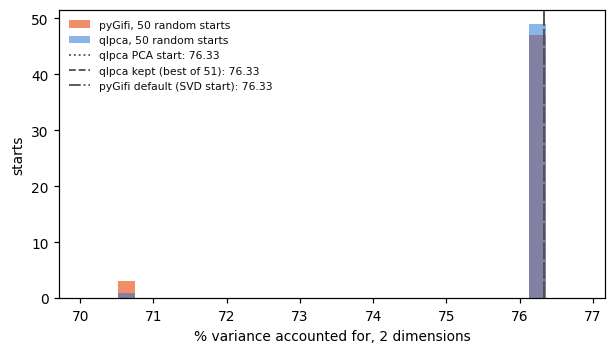

In [11]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.linspace(min(vaf_pg.min(), vaf_q.min()) - 0.5, max(vaf_pg.max(), vaf_q.max()) + 0.5, 30)
ax.hist(vaf_pg, bins=bins, color=c.ORANGE, alpha=0.75, label="pyGifi, 50 random starts")
ax.hist(vaf_q[1:], bins=bins, color=c.BLUE, alpha=0.55, label="qlpca, 50 random starts")
for i, (lab, v) in enumerate(marks.items()):
    ax.axvline(v, color=c.INK if "R" in lab else c.INK2, ls=[":", "--", "-.", "-", (0, (1, 3))][i % 5], lw=1.2, label=f"{lab}: {v:.2f}")
ax.set_xlabel("% variance accounted for, 2 dimensions"); ax.set_ylabel("starts")
ax.legend(fontsize=7, frameon=False, loc="upper left")
c.save_figure(fig, "nb_e_local_optima_st_gender_knots2")
plt.show()

## f) Monotone transformations: `monotone=True` vs `ordinal=TRUE`

Same knots (2), degree 1 and degree 2, three data sets (`eps=1e-8`; manifest). qlpca: I-splines with
non-negative coefficients (NNLS), monotone everywhere by construction. princals: Dykstra's alternating
projections between the spline space and the cone of vectors isotone in the data, which constrains the
function only at the data points. For degree 1 the two feasible sets coincide; for degree 2 they do not.

In [12]:
cols = ["dataset", "run", "qlpca_vaf2", "pygifi_vaf2", "gifi_r_vaf2", "qlpca_vs_pygifi_evals",
        "qlpca_vs_pygifi_transform_corr", "qlpca_ntel", "pygifi_ntel"]
mono = summary[summary.run.isin(["monotone_deg1", "monotone_deg2"])].reindex(columns=cols)
mono

,dataset,run,qlpca_vaf2,pygifi_vaf2,gifi_r_vaf2,qlpca_vs_pygifi_evals,qlpca_vs_pygifi_transform_corr,qlpca_ntel,pygifi_ntel
2,cylinder_0,monotone_deg1,97.424362,97.424358,NaN,0.000651,3.089765e-07,32,39
3,cylinder_0,monotone_deg2,97.926298,98.422153,NaN,0.111805,2.598697e-02,47,63
13,st_gender,monotone_deg1,71.030476,71.030492,NaN,0.000001,1.516619e-07,22,29
14,st_gender,monotone_deg2,71.218216,71.486128,NaN,0.019831,1.409212e-03,90,79
18,neumann,monotone_deg1,99.819526,99.819522,NaN,0.000029,2.598657e-07,49,42
19,neumann,monotone_deg2,99.879136,99.879131,NaN,0.000059,1.608231e-06,90,45


In [13]:
def min_slope_sign(model, j):
    # smallest increment of the qlpca transformation on a fine grid over the training range
    _, f = model.variable_transformation(j, n_points=2001)
    return np.diff(f).min()


def data_isotone(x, t):
    o = np.argsort(x, kind="stable")
    return np.diff(t[o]).min()


rows = []
for name in ("st_gender", "cylinder_0", "neumann"):
    df = c.load_dataset(name, MAN)
    res = fits[name, "monotone_deg2"]
    mq = res["qlpca"]["model"]
    for j, col in enumerate(df.columns):
        x = df[col].to_numpy()
        tp = res["pygifi"]["transform"][:, j] * np.sign(np.corrcoef(res["pygifi"]["transform"][:, j], x)[0, 1])
        rows.append({"dataset": name, "variable": col,
                     "qlpca: min increment on a 2001-point grid": min_slope_sign(mq, j),
                     "princals: min increment between sorted data": data_isotone(x, tp)})
pd.DataFrame(rows).groupby("dataset").min(numeric_only=True)

,qlpca: min increment on a 2001-point grid,princals: min increment between sorted data
dataset,,
cylinder_0,3.470616e-07,-0.001245
neumann,2.142820e-04,0.000000
st_gender,-1.110223e-15,-0.000390


A negative minimum increment means the transformation decreases somewhere. For qlpca the value is zero up to
rounding (the I-spline coefficients are non-negative). For princals, values below zero mean that the returned
transformation is not exactly isotone in the data: Dykstra's loop stops when `max(abs(x1 - x2)) < eps` and
returns the average `(x1 + x2) / 2` of the last spline-space and cone projections
([`R/coneRegression.R:96-104`](https://github.com/cran/Gifi/blob/1.0-0/R/coneRegression.R#L96-L104)), which need
not lie in the cone.

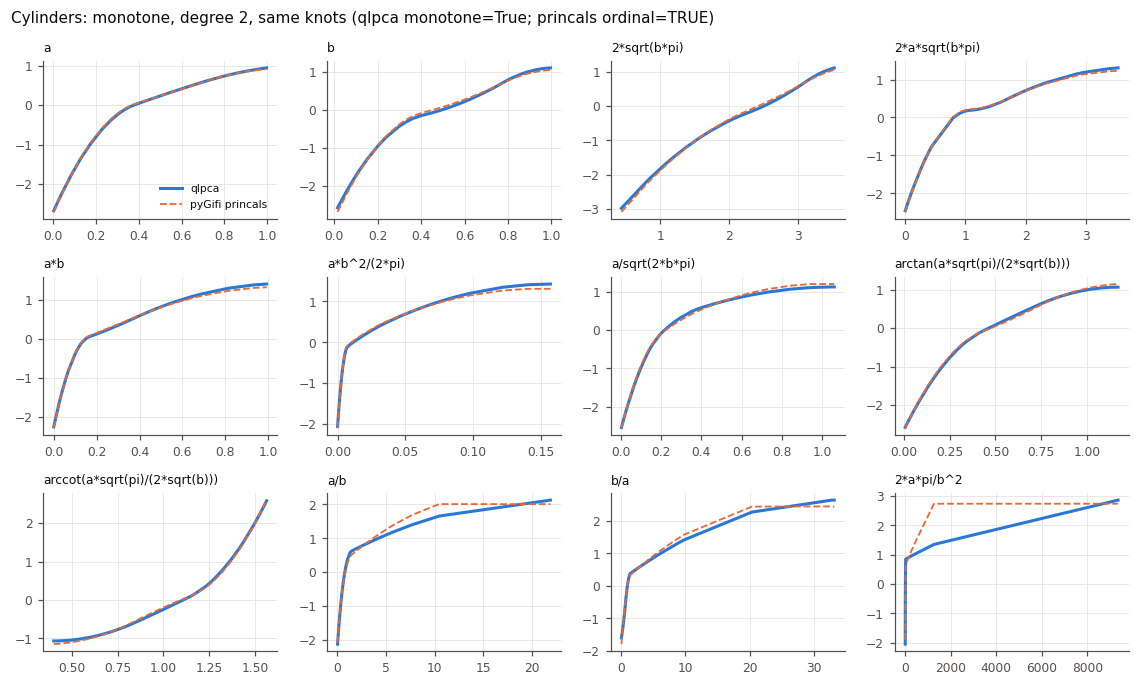

In [14]:
fig = c.plot_transformations(c.load_dataset("cylinder_0", MAN), fits["cylinder_0", "monotone_deg2"],
                             title="Cylinders: monotone, degree 2, same knots (qlpca monotone=True; princals ordinal=TRUE)")
c.save_figure(fig, "nb_f_monotone_deg2_transformations_cylinder_0")
plt.show()

## g) What only qlpca does

Gas turbine data: fit on the 2015 sample; project 400 hourly records of 2014 (another reproducible sample) with
`transform`; reconstruct with `inverse_transform` (exact where f_j is monotone; where it is not, the inverse is not
unique); piecewise loadings; use in a scikit-learn `Pipeline`.
pyGifi's `Princals.transform` returns the training object scores whatever the input
([`models/princals.py:334-345`](https://github.com/vam-math/pyGifi/blob/7aa81ed/pygifi/models/princals.py#L334-L345):
"Out-of-sample projection is not supported, which is also true in R").

In [15]:
spec = MAN["datasets"]["gas_turbine"]
train = c.load_dataset("gas_turbine", MAN)
new = c.gas_turbine_year(2014)[spec["variables"]].sample(n=400, random_state=2014).reset_index(drop=True)
model = QLPCA(n_components=2, n_knots=2, random_state=0).fit(train)

with warnings.catch_warnings(record=True) as rec:
    warnings.simplefilter("always")
    S_new = model.transform(new)
for w in rec:
    if issubclass(w.category, ExtrapolationWarning):
        print("ExtrapolationWarning:", w.message)
print("training scores range:", model.scores_.min().round(2), model.scores_.max().round(2),
      "| 2014 scores range:", S_new.min().round(2), S_new.max().round(2))

p = c.run_pygifi(train, "knots2", MAN, "gas_turbine")["model"]
print("pyGifi transform(new 2014 rows) has shape", np.shape(p.transform(new)),
      "and equals the training scores:", np.allclose(p.transform(new), p.result_["objectscores"]))

training scores range: -3.13 2.96 | 2014 scores range: -2.51 2.56


pyGifi transform(new 2014 rows) has shape (400, 2) and equals the training scores: True


In [16]:
full = QLPCA(n_components=train.shape[1], n_knots=2, random_state=0).fit(train)
rec_ = full.inverse_transform(full.scores_)
err = np.abs(rec_ - train.to_numpy()) / train.std().to_numpy()
monotone_f = np.array([np.all(np.diff(full.variable_transformation(j)[1]) > 0) or
                       np.all(np.diff(full.variable_transformation(j)[1]) < 0) for j in range(train.shape[1])])
print("reconstruction of the training data with p = m (inverse_transform of the scores):")
for label, sel in (("monotone", monotone_f), ("non-monotone", ~monotone_f)):
    if sel.any():
        print(f"  {sel.sum()} variable(s) with a {label} f_j ({', '.join(train.columns[sel])}): max error "
              f"{err[:, sel].max():.2e} sd; rows with error > 1e-6 sd: {(err[:, sel] > 1e-6).any(axis=1).mean():.0%}")
    else:
        print(f"  no variable has a {label} f_j")
print("  (where f_j is not monotone its inverse is not unique and inverse_transform uses the first segment)")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    print(f"  the reconstructed rows map back to the same transformed values: max |f(rec) - F| = "
          f"{np.abs(full.transform_variables(rec_) - full.transformed_).max():.1e}")

from qlpca.diagnostics import piecewise_loadings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)        # piecewise_loadings passes a plain array
    pl = piecewise_loadings(model, train)
rows = []
for j, col in enumerate(train.columns):
    d = pl[j]
    for s in range(len(d["slope_sign"])):
        rows.append({"variable": col, "segment": f"[{d['edges'][s]:.2f}, {d['edges'][s + 1]:.2f}]", "n": d["n"][s],
                     "loading D1": d["loadings"][s][0], "loading D2": d["loadings"][s][1]})
pd.DataFrame(rows).query("variable in ['TIT', 'TAT', 'AT']")

reconstruction of the training data with p = m (inverse_transform of the scores):
  no variable has a monotone f_j
  9 variable(s) with a non-monotone f_j (AT, AP, AH, AFDP, GTEP, TIT, TAT, TEY, CDP): max error 6.17e+00 sd; rows with error > 1e-6 sd: 96%
  (where f_j is not monotone its inverse is not unique and inverse_transform uses the first segment)
  the reconstructed rows map back to the same transformed values: max |f(rec) - F| = 4.6e-14


,variable,segment,n,loading D1,loading D2
0,AT,"[-4.36, 13.00]",132,-0.053353,0.450794
1,AT,"[13.00, 21.38]",136,0.306488,0.456498
2,AT,"[21.38, 37.10]",132,0.397303,0.765095
15,TIT,"[1023.80, 1074.70]",133,-0.322530,0.077813
16,TIT,"[1074.70, 1097.25]",137,0.893947,0.299481
17,TIT,"[1097.25, 1100.20]",132,0.329554,-0.113793
18,TAT,"[523.18, 545.88]",132,-0.530590,0.816301
19,TAT,"[545.88, 549.93]",138,-0.675602,-0.303303
20,TAT,"[549.93, 550.44]",136,0.060493,0.082250


In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

gas = c.gas_turbine_year(spec["year"]).sample(n=spec["n"], random_state=spec["random_state"]).sort_index()
Xg, yg = gas[spec["variables"]].reset_index(drop=True), gas["NOX"].to_numpy()
cv = KFold(5, shuffle=True, random_state=0)
pipes = {"StandardScaler + PCA(2) + LinearRegression": make_pipeline(StandardScaler(), PCA(2), LinearRegression()),
         "QLPCA(2, n_knots=2) + LinearRegression": make_pipeline(QLPCA(2, n_knots=2, n_init=2, random_state=0), LinearRegression())}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ExtrapolationWarning)     # validation folds are new data
    scores = {k: cross_val_score(v, Xg, yg, cv=cv, scoring="r2") for k, v in pipes.items()}
pd.DataFrame({k: {"mean R² (5-fold)": v.mean(), "sd": v.std()} for k, v in scores.items()}).T

,mean R² (5-fold),sd
StandardScaler + PCA(2) + LinearRegression,0.354572,0.079189
"QLPCA(2, n_knots=2) + LinearRegression",0.271597,0.067803


The pipeline is shown to illustrate the interface (cloning, fitting inside cross-validation folds); qlPCA is a
descriptive method and this is not a claim about prediction. The validation folds are new data, so
`ExtrapolationWarning`s are issued and silenced here.

## h) Conclusions

The statements below are computed from the cells above (pyGifi) and, where the JSON files are present, from
Gifi (R).

In [18]:
lines = []
s = summary[summary.run.isin(["knots1", "knots2"])]
lines.append(f"1. Same knots, degree 1, no monotonicity: qlpca and pyGifi agree within the manifest tolerances in "
             f"{int(s.qlpca_vs_pygifi_within_tol.sum())} of {len(s)} cases (6 data sets x 1 and 2 knots); largest "
             f"eigenvalue difference {s.qlpca_vs_pygifi_evals.max():.1e}, largest 1-|r| between transformations "
             f"{s.qlpca_vs_pygifi_transform_corr.max():.1e}.")
if "qlpca_vs_gifi_r_within_tol" in s and s.qlpca_vs_gifi_r_within_tol.notna().any():
    lines.append(f"   Against Gifi (R): {int(s.qlpca_vs_gifi_r_within_tol.sum())} of {int(s.qlpca_vs_gifi_r_within_tol.notna().sum())} cases within tolerance.")
else:
    lines.append("   Against Gifi (R): pending.")
lines.append("2. princals does not discretise numeric variables: numeric columns are used as they are and the "
             "spline basis is built on the original values (section a).")
lines.append(f"3. B-splines and [1, I-splines] span the same space (max projector difference "
             f"{basis['max |P_B - P_[1,I]|'].max():.1e}); condition numbers with 10 knots, degree 1: "
             f"{basis.query('degree == 1 and `interior knots` == 10')['cond(B)'].iloc[0]:.1f} (B) vs "
             f"{basis.query('degree == 1 and `interior knots` == 10')['cond([1, I])'].iloc[0]:.1f} ([1, I]).")
d = defaults.set_index("dataset")
lines.append("4. Defaults (VAF of 2 dimensions, %): " + "; ".join(
    f"{k}: PCA {r['linear PCA']:.1f}, qlpca {r['qlpca default']:.1f}, princals {r['princals default (pyGifi)']:.1f} "
    f"({r['params/variable princals']:.0f} vs {r['params/variable qlpca']:.0f} parameters per variable)"
    for k, r in d.iterrows()) + ".")
lines.append(f"5. Chapter 4 data, 2 knots: 50 random starts of pyGifi reach VAF between {vaf_pg.min():.2f} and "
             f"{vaf_pg.max():.2f}; the qlpca PCA start gives {vaf_q[0]:.2f}; the best of qlpca's 51 starts {vaf_q.max():.2f}.")
mo = summary[summary.run == "monotone_deg1"]
mo2 = summary[summary.run == "monotone_deg2"]
lines.append(f"6. Monotone, degree 1: largest eigenvalue difference qlpca-pyGifi {mo.qlpca_vs_pygifi_evals.max():.1e}. "
             f"Degree 2: VAF qlpca vs pyGifi " + "; ".join(
                 f"{r.dataset} {r.qlpca_vaf2:.2f} vs {r.pygifi_vaf2:.2f}" for r in mo2.itertuples()) + ".")
lines.append("7. Only qlpca projects new observations (with ExtrapolationWarning outside the training range), "
             "reconstructs data (exactly for variables with a monotone transformation; gas turbine, p = m: "
             f"{int((~monotone_f).sum())} of {len(monotone_f)} transformations are not monotone, so their reconstruction is not unique), "
             "reports piecewise loadings and works as a scikit-learn transformer; pyGifi's transform returns the "
             "training scores whatever the input.")
print("\n".join(lines))

1. Same knots, degree 1, no monotonicity: qlpca and pyGifi agree within the manifest tolerances in 12 of 12 cases (6 data sets x 1 and 2 knots); largest eigenvalue difference 9.0e-06, largest 1-|r| between transformations 2.0e-10.
   Against Gifi (R): pending.
2. princals does not discretise numeric variables: numeric columns are used as they are and the spline basis is built on the original values (section a).
3. B-splines and [1, I-splines] span the same space (max projector difference 1.9e-15); condition numbers with 10 knots, degree 1: 1.8 (B) vs 26.4 ([1, I]).
4. Defaults (VAF of 2 dimensions, %): cylinder_0: PCA 82.2, qlpca 95.2, princals 100.0 (50 vs 2 parameters per variable); cylinder_10: PCA 79.5, qlpca 93.7, princals 100.0 (50 vs 2 parameters per variable); cylinder_25: PCA 69.5, qlpca 89.2, princals 100.0 (50 vs 2 parameters per variable); st_gender: PCA 61.9, qlpca 68.9, princals 82.9 (14 vs 2 parameters per variable); neumann: PCA 98.8, qlpca 99.7, princals 100.0 (41 vs 2

### References

* Gifi, A. (1990; cited in the thesis as 1991). *Nonlinear Multivariate Analysis*. Wiley. (`gifi1991nonlinear`)
* Lavado, N. & Calapez, T. (2011). Principal Components Analysis with Spline Optimal Transformations for
  Continuous Data. *IAENG International Journal of Applied Mathematics*, 41(4), 367–375. (`lavado2011ijam`)
* Lavado, N. (2012). *Extensões via splines da Análise em Componentes Principais*. PhD thesis, ISCTE-IUL. (`lavado2012phd`)
* Mair, P., De Leeuw, J. & Groenen, P. J. F. *Gifi: Multivariate Analysis with Optimal Scaling*. R package 1.0-0 (2025).
  doi:10.32614/CRAN.package.Gifi. GPL-3. (`mair2025gifi`)
* Perumal, V. et al. *pyGifi* 0.1.0, commit 7aa81ed. https://github.com/vam-math/pyGifi. GPL-3. (`perumal2025pygifi`)
* Kaya, H., Tüfekci, P. & Uzun, E. (2019). Predicting CO and NOx emissions from gas turbines: novel data and a
  benchmark PEMS. *Turkish Journal of Electrical Engineering and Computer Sciences*, 27, 4783–4796.
  (`kaya2019gasturbine`) Data: UCI Machine Learning Repository, doi:10.24432/C5WC95, CC BY 4.0 (`uci2019gasturbine`).